In [1]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd

df = pd.read_csv("kronodroid_permissions.csv")
with open("permissions.txt") as f:
    permissions = [ligne.strip() for ligne in f if ligne.strip()]

X = df[permissions]   # les features : les 166 permissions
y = df["Malware"]     # l'étiquette : 1 = malware, 0 = saine
print(X.shape, y.value_counts().to_dict())

(76716, 166) {1: 40934, 0: 35782}


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

modele = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
modele.fit(X_train, y_train)
pred = modele.predict(X_test)

print(classification_report(y_test, pred, target_names=["saine", "malware"], digits=3))
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"Faux positifs (applications saines signalées à tort) : {fp} → taux {fp / (fp + tn):.1%}")
print(f"Faux négatifs (malwares manqués) : {fn} → taux {fn / (fn + tp):.1%}")

              precision    recall  f1-score   support

       saine      0.934     0.961     0.947      7157
     malware      0.965     0.941     0.953      8187

    accuracy                          0.950     15344
   macro avg      0.950     0.951     0.950     15344
weighted avg      0.951     0.950     0.950     15344

Faux positifs (applications saines signalées à tort) : 279 → taux 3.9%
Faux négatifs (malwares manqués) : 485 → taux 5.9%


In [4]:
ANNEE_COUPURE = 2013
train = df[df["annee"] <= ANNEE_COUPURE]
test_brut = df[df["annee"] > ANNEE_COUPURE]
print("Entraînement (2008-2013) :", train["Malware"].value_counts().to_dict())
print("Test brut (2014-2020) :", test_brut["Malware"].value_counts().to_dict())

Entraînement (2008-2013) : {0: 29691, 1: 19451}
Test brut (2014-2020) : {1: 21483, 0: 6091}


In [5]:
morceaux = []
for annee, groupe in test_brut.groupby("annee"):
    sains = groupe[groupe["Malware"] == 0]
    malwares = groupe[groupe["Malware"] == 1]
    n_malwares = min(len(malwares), round(len(sains) / 9))
    morceaux.append(sains)
    morceaux.append(malwares.sample(n=n_malwares, random_state=42))

test = pd.concat(morceaux)
print("Test réaliste :", test["Malware"].value_counts().to_dict(),
      f"→ {test['Malware'].mean():.1%} de malwares")

Test réaliste : {0: 6091, 1: 676} → 10.0% de malwares


In [6]:
modele_t = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
modele_t.fit(train[permissions], train["Malware"])
pred_t = modele_t.predict(test[permissions])

print(classification_report(test["Malware"], pred_t, target_names=["saine", "malware"], digits=3))
tn, fp, fn, tp = confusion_matrix(test["Malware"], pred_t).ravel()
print(f"Faux positifs : {fp} → taux {fp / (fp + tn):.1%}")
print(f"Faux négatifs : {fn} → taux {fn / (fn + tp):.1%}")

              precision    recall  f1-score   support

       saine      0.988     0.917     0.951      6091
     malware      0.545     0.896     0.678       676

    accuracy                          0.915      6767
   macro avg      0.767     0.907     0.815      6767
weighted avg      0.943     0.915     0.924      6767

Faux positifs : 505 → taux 8.3%
Faux négatifs : 70 → taux 10.4%


In [7]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


,annee,applications,precision,rappel,f1_malware
0,2014,702,0.680000,0.971429,0.800000
1,2015,801,0.442953,0.825000,0.576419
2,2016,826,0.442308,0.831325,0.577406
3,2017,724,0.563025,0.930556,0.701571
4,2018,867,0.541667,0.896552,0.675325
5,2019,1674,0.593156,0.934132,0.725581
6,2020,1173,0.566667,0.871795,0.686869


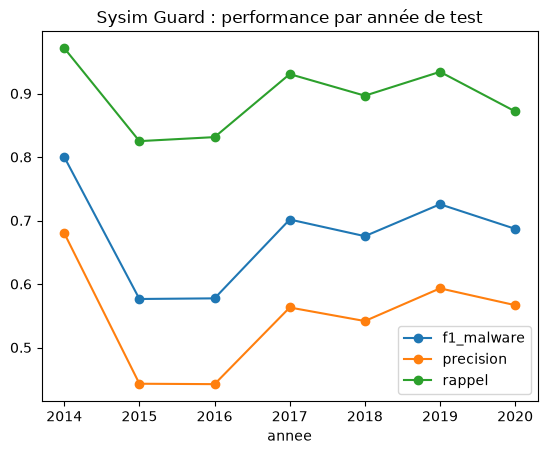

In [8]:
from sklearn.metrics import f1_score, precision_score, recall_score

lignes = []
for annee, groupe in test.groupby("annee"):
    p = modele_t.predict(groupe[permissions])
    lignes.append({
        "annee": int(annee),
        "applications": len(groupe),
        "precision": precision_score(groupe["Malware"], p, zero_division=0),
        "rappel": recall_score(groupe["Malware"], p, zero_division=0),
        "f1_malware": f1_score(groupe["Malware"], p, zero_division=0),
    })

par_annee = pd.DataFrame(lignes)
par_annee.plot(x="annee", y=["f1_malware", "precision", "rappel"], marker="o",
               title="Sysim Guard : performance par année de test")
par_annee

In [9]:
import numpy as np

def evaluer_seuils(y_vrai, proba, seuils):
    lignes = []
    for s in seuils:
        p = (proba >= s).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_vrai, p, labels=[0, 1]).ravel()
        taux_fp = fp / (fp + tn)
        lignes.append({
            "seuil": s,
            "precision": tp / (tp + fp) if (tp + fp) else 0,
            "rappel": tp / (tp + fn),
            "f1": f1_score(y_vrai, p, zero_division=0),
            "taux_faux_positifs": taux_fp,
            "fausses_alertes_sur_80_apps": round(taux_fp * 80, 1),
        })
    return pd.DataFrame(lignes)

seuils = np.round(np.arange(0.50, 0.96, 0.05), 2)

In [10]:
train_a = train[train["annee"] <= 2012]
val_brut = train[train["annee"] == 2013]
n_val_malwares = round((val_brut["Malware"] == 0).sum() / 9)
val = pd.concat([
    val_brut[val_brut["Malware"] == 0],
    val_brut[val_brut["Malware"] == 1].sample(n=n_val_malwares, random_state=42),
])
print("Validation 2013 :", val["Malware"].value_counts().to_dict())

modele_val = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
modele_val.fit(train_a[permissions], train_a["Malware"])
proba_val = modele_val.predict_proba(val[permissions])[:, 1]
evaluer_seuils(val["Malware"], proba_val, seuils)

Validation 2013 : {0: 489, 1: 54}


,seuil,precision,rappel,f1,taux_faux_positifs,fausses_alertes_sur_80_apps
0,0.50,0.701493,0.870370,0.776860,0.040900,3.3
1,0.55,0.718750,0.851852,0.779661,0.036810,2.9
2,0.60,0.779661,0.851852,0.814159,0.026585,2.1
3,0.65,0.779661,0.851852,0.814159,0.026585,2.1
4,0.70,0.779661,0.851852,0.814159,0.026585,2.1
5,0.75,0.821429,0.851852,0.836364,0.020450,1.6
6,0.80,0.849057,0.833333,0.841121,0.016360,1.3
7,0.85,0.891304,0.759259,0.820000,0.010225,0.8
8,0.90,0.909091,0.740741,0.816327,0.008180,0.7
9,0.95,0.916667,0.611111,0.733333,0.006135,0.5


In [11]:
SEUIL = 0.80
proba_test = modele_t.predict_proba(test[permissions])[:, 1]
evaluer_seuils(test["Malware"], proba_test, [0.50, SEUIL])

,seuil,precision,rappel,f1,taux_faux_positifs,fausses_alertes_sur_80_apps
0,0.5,0.545455,0.89645,0.678232,0.082909,6.6
1,0.8,0.718182,0.58432,0.644372,0.025447,2.0


In [12]:
import os
print("Je suis dans :", os.getcwd())
print("Dossier parent :", os.listdir(".."))
print("Deux niveaux au-dessus :", os.listdir("../.."))

Je suis dans : C:\Users\chris\kronodroid\real_device
Dossier parent : ['.git', 'emulator', 'publist.md', 'README.md', 'real_device']
Deux niveaux au-dessus : ['.android', '.antigravity-ide', '.aws', '.azure', '.bash_history', '.cache', '.claude', '.claude.json', '.claude.json.backup', '.copilot', '.dbus-keyrings', '.docker', '.emulator_console_auth_token', '.ganttproject', '.ganttproject.d', '.gemini', '.gitconfig', '.gradle', '.icesoft', '.ipython', '.jupyter', '.kube', '.lesshst', '.local', '.minikube', '.mitmproxy', '.openjfx', '.pdfbox.cache', '.python_history', '.redhat', '.ssh', '.vagrant.d', '.viminfo', '.VirtualBox', '.vscode', '.vscode-shared', 'Analyse_firware', 'AndroidStudioProjects', 'androzoo', 'AppData', 'Application Data', 'Claude', 'config.xml', 'Contacts', 'Cookies', 'copy', 'CrossDevice', 'curl', 'Desktop', 'desktop.ini', 'dist-etudiant', 'Docker-Node_Express', 'Documents', 'Downloads', 'ec2-user@ec2-34-207-189-112.compute-1.amazonaws.com', 'Favorites', 'flutter', 'g

In [13]:
import pandas as pd

colonnes = ["sha256", "sha1", "md5", "dex_date", "apk_size", "pkg_name",
            "vercode", "vt_detection", "vt_scan_date", "dex_size", "added", "markets"]

echantillons = []
for annee in ["2012", "2013"]:
    d = pd.read_csv(f"../../androzoo/sains_{annee}.csv", names=colonnes, low_memory=False)
    d = d.drop_duplicates("pkg_name")          # une seule version par application
    tir = d.sample(n=1000, random_state=42)
    tir["annee"] = annee
    echantillons.append(tir)

a_telecharger = pd.concat(echantillons)
a_telecharger[["sha256", "pkg_name", "annee"]].to_csv("a_telecharger.csv", index=False)
print(a_telecharger["annee"].value_counts().to_dict())

{'2012': 1000, '2013': 1000}


In [14]:
%pip install androguard


Note: you may need to restart the kernel to use updated packages.


In [15]:
script = r'''
import os, sys, subprocess, csv
import pandas as pd
from androguard.core.apk import APK

CLE = os.environ["ANDROZOO_KEY"]
liste = pd.read_csv("a_telecharger.csv")

# Charger les 166 permissions attendues (fin du nom, comme KronoDroid)
with open("permissions.txt") as f:
    attendues = [l.strip() for l in f if l.strip()]

resultats = []
echecs = 0
for i, row in liste.iterrows():
    sha = row["sha256"]
    apk = f"{sha}.apk"
    url = f"https://androzoo.uni.lu/api/download?apikey={CLE}&sha256={sha}"
    try:
        subprocess.run(["curl", "-s", "-o", apk, url], check=True, timeout=120)
        a = APK(apk)
        perms = set(p.split(".")[-1] for p in a.get_permissions())
        ligne = {perm: (1 if perm in perms else 0) for perm in attendues}
        ligne["sha256"] = sha
        ligne["annee"] = row["annee"]
        ligne["Malware"] = 0
        resultats.append(ligne)
    except Exception as e:
        echecs += 1
        print(f"[{i}] echec {sha[:12]} : {e}", flush=True)
    finally:
        if os.path.exists(apk):
            os.remove(apk)          # suppression immediate de l'APK
    if (i + 1) % 50 == 0:
        pd.DataFrame(resultats).to_csv("sains_recents_permissions.csv", index=False)
        print(f"{i+1}/{len(liste)} traites, {echecs} echecs", flush=True)

pd.DataFrame(resultats).to_csv("sains_recents_permissions.csv", index=False)
print(f"TERMINE : {len(resultats)} applications, {echecs} echecs")
'''
with open("extraire_permissions.py", "w") as f:
    f.write(script)
print("Script écrit.")

Script écrit.


In [16]:
with open("extraire_permissions.py") as f:
    contenu = f.read()
contenu_test = contenu.replace(
    'liste = pd.read_csv("a_telecharger.csv")',
    'liste = pd.read_csv("a_telecharger.csv").head(10)'
)
contenu_test = contenu_test.replace(
    '"sains_recents_permissions.csv"', '"test_10.csv"'
)
with open("extraire_test.py", "w") as f:
    f.write(contenu_test)
print("Script de test écrit.")

Script de test écrit.


In [17]:
script = r'''
import os, sys, subprocess
import pandas as pd
from androguard.misc import AnalyzeAPK

CLE = os.environ["ANDROZOO_KEY"]
liste = pd.read_csv("a_telecharger.csv")

with open("permissions.txt") as f:
    attendues = [l.strip() for l in f if l.strip()]

resultats = []
echecs = 0
for i, row in liste.iterrows():
    sha = row["sha256"]
    apk = f"{sha}.apk"
    url = f"https://androzoo.uni.lu/api/download?apikey={CLE}&sha256={sha}"
    try:
        subprocess.run(["curl", "-s", "-o", apk, url], check=True, timeout=120)
        a, _, _ = AnalyzeAPK(apk)
        perms = set(p.split(".")[-1] for p in a.get_permissions())
        ligne = {perm: (1 if perm in perms else 0) for perm in attendues}
        ligne["sha256"] = sha
        ligne["annee"] = row["annee"]
        ligne["Malware"] = 0
        resultats.append(ligne)
    except Exception as e:
        echecs += 1
        print(f"[{i}] echec {sha[:12]} : {e}", flush=True)
    finally:
        if os.path.exists(apk):
            os.remove(apk)
    if (i + 1) % 50 == 0:
        pd.DataFrame(resultats).to_csv("sains_recents_permissions.csv", index=False)
        print(f"{i+1}/{len(liste)} traites, {echecs} echecs", flush=True)

pd.DataFrame(resultats).to_csv("sains_recents_permissions.csv", index=False)
print(f"TERMINE : {len(resultats)} applications, {echecs} echecs")
'''
with open("extraire_permissions.py", "w") as f:
    f.write(script)
print("Script corrigé écrit.")

Script corrigé écrit.


In [18]:
script = r'''
import os, sys, subprocess
import pandas as pd
from androguard.misc import AnalyzeAPK

CLE = os.environ["ANDROZOO_KEY"]
liste = pd.read_csv("a_telecharger.csv")

with open("permissions.txt") as f:
    attendues = [l.strip() for l in f if l.strip()]

resultats = []
echecs = 0
for i, row in liste.iterrows():
    sha = row["sha256"]
    apk = f"{sha}.apk"
    url = f"https://androzoo.uni.lu/api/download?apikey={CLE}&sha256={sha}"
    try:
        subprocess.run(["curl", "-s", "-o", apk, url], check=True, timeout=120)
        a, _, _ = AnalyzeAPK(apk)
        perms = set(p.split(".")[-1] for p in a.get_permissions())
        ligne = {perm: (1 if perm in perms else 0) for perm in attendues}
        ligne["sha256"] = sha
        ligne["annee"] = row["annee"]
        ligne["Malware"] = 0
        resultats.append(ligne)
    except Exception as e:
        echecs += 1
        print(f"[{i}] echec {sha[:12]} : {e}", flush=True)
    finally:
        if os.path.exists(apk):
            os.remove(apk)
    if (i + 1) % 50 == 0:
        pd.DataFrame(resultats).to_csv("sains_recents_permissions.csv", index=False)
        print(f"{i+1}/{len(liste)} traites, {echecs} echecs", flush=True)

pd.DataFrame(resultats).to_csv("sains_recents_permissions.csv", index=False)
print(f"TERMINE : {len(resultats)} applications, {echecs} echecs")
'''
with open("extraire_permissions.py", "w") as f:
    f.write(script)
print("Script corrigé écrit.")

Script corrigé écrit.


In [19]:
with open("extraire_permissions.py") as f:
    contenu = f.read()
contenu_test = contenu.replace(
    'liste = pd.read_csv("a_telecharger.csv")',
    'liste = pd.read_csv("a_telecharger.csv").head(10)'
).replace('"sains_recents_permissions.csv"', '"test_10.csv"')
with open("extraire_test.py", "w") as f:
    f.write(contenu_test)
print("Script de test corrigé écrit.")

Script de test corrigé écrit.


In [20]:
import pandas as pd
deja = set(pd.read_csv("sains_recents_permissions.csv")["sha256"])
print("Déjà traitées :", len(deja))

with open("extraire_permissions.py") as f:
    contenu = f.read()

# Reprendre là où on s'est arrêté, sans écraser l'existant
contenu_reprise = contenu.replace(
    'liste = pd.read_csv("a_telecharger.csv")',
    'liste = pd.read_csv("a_telecharger.csv")\n'
    'deja = set(pd.read_csv("sains_recents_permissions.csv")["sha256"])\n'
    'liste = liste[~liste["sha256"].isin(deja)].reset_index(drop=True)\n'
    'resultats_existants = pd.read_csv("sains_recents_permissions.csv").to_dict("records")'
).replace(
    'resultats = []',
    'resultats = resultats_existants'
)
with open("extraire_reprise.py", "w") as f:
    f.write(contenu_reprise)
print("Script de reprise écrit.")

Déjà traitées : 1993
Script de reprise écrit.


In [21]:
import pandas as pd
deja = set(pd.read_csv("sains_recents_permissions.csv")["sha256"])
print("Déjà traitées :", len(deja))

with open("extraire_permissions.py") as f:
    contenu = f.read()

# Reprendre là où on s'est arrêté, sans écraser l'existant
contenu_reprise = contenu.replace(
    'liste = pd.read_csv("a_telecharger.csv")',
    'liste = pd.read_csv("a_telecharger.csv")\n'
    'deja = set(pd.read_csv("sains_recents_permissions.csv")["sha256"])\n'
    'liste = liste[~liste["sha256"].isin(deja)].reset_index(drop=True)\n'
    'resultats_existants = pd.read_csv("sains_recents_permissions.csv").to_dict("records")'
).replace(
    'resultats = []',
    'resultats = resultats_existants'
)
with open("extraire_reprise.py", "w") as f:
    f.write(contenu_reprise)
print("Script de reprise écrit.")

Déjà traitées : 1993
Script de reprise écrit.


In [22]:
import pandas as pd

recents = pd.read_csv("sains_recents_permissions.csv")
print("Applications extraites :", len(recents))

# Vérifier le statut actuel sur la liste AndroZoo complète
liste_az = pd.read_csv(
    "../../androzoo/latest_with-added-date.csv.gz",
    usecols=["sha256", "vt_detection"], low_memory=False
)
liste_az["sha256"] = liste_az["sha256"].str.upper()
recents = recents.merge(liste_az, on="sha256", how="left")

print(recents["vt_detection"].describe())
suspectes = recents[recents["vt_detection"].fillna(0) > 0]
print("Devenues suspectes depuis :", len(suspectes))

Applications extraites : 1993
count    1993.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: vt_detection, dtype: float64
Devenues suspectes depuis : 0


In [23]:
# Aligner les colonnes des applications récentes sur celles du modèle
recents_features = recents[permissions].copy()
recents_features["Malware"] = 0
recents_features["annee"] = recents["annee"].astype(int)

# Entraînement enrichi = entraînement d'origine (≤2013) + applications saines récentes
train_enrichi = pd.concat([train[permissions + ["Malware", "annee"]], recents_features],
                          ignore_index=True)

print("Entraînement d'origine :", train["Malware"].value_counts().to_dict())
print("Entraînement enrichi   :", train_enrichi["Malware"].value_counts().to_dict())

# Même algorithme, mêmes réglages que les expériences 1 et 2
modele_e = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
modele_e.fit(train_enrichi[permissions], train_enrichi["Malware"])
pred_e = modele_e.predict(test[permissions])

print(classification_report(test["Malware"], pred_e, target_names=["saine", "malware"], digits=3))
tn, fp, fn, tp = confusion_matrix(test["Malware"], pred_e).ravel()
print(f"Faux positifs : {fp} → taux {fp / (fp + tn):.1%}")
print(f"Faux négatifs : {fn} → taux {fn / (fn + tp):.1%}")

Entraînement d'origine : {0: 29691, 1: 19451}
Entraînement enrichi   : {0: 31684, 1: 19451}
              precision    recall  f1-score   support

       saine      0.986     0.922     0.953      6091
     malware      0.556     0.882     0.682       676

    accuracy                          0.918      6767
   macro avg      0.771     0.902     0.817      6767
weighted avg      0.943     0.918     0.926      6767

Faux positifs : 476 → taux 7.8%
Faux négatifs : 80 → taux 11.8%


In [24]:
# Aligner les colonnes des applications récentes sur celles du modèle
recents_features = recents[permissions].copy()
recents_features["Malware"] = 0
recents_features["annee"] = recents["annee"].astype(int)

# Entraînement enrichi = entraînement d'origine (≤2013) + applications saines récentes
train_enrichi = pd.concat([train[permissions + ["Malware", "annee"]], recents_features],
                          ignore_index=True)

print("Entraînement d'origine :", train["Malware"].value_counts().to_dict())
print("Entraînement enrichi   :", train_enrichi["Malware"].value_counts().to_dict())

# Même algorithme, mêmes réglages que les expériences 1 et 2
modele_e = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
modele_e.fit(train_enrichi[permissions], train_enrichi["Malware"])
pred_e = modele_e.predict(test[permissions])

print(classification_report(test["Malware"], pred_e, target_names=["saine", "malware"], digits=3))
tn, fp, fn, tp = confusion_matrix(test["Malware"], pred_e).ravel()
print(f"Faux positifs : {fp} → taux {fp / (fp + tn):.1%}")
print(f"Faux négatifs : {fn} → taux {fn / (fn + tp):.1%}")

Entraînement d'origine : {0: 29691, 1: 19451}
Entraînement enrichi   : {0: 31684, 1: 19451}
              precision    recall  f1-score   support

       saine      0.986     0.922     0.953      6091
     malware      0.556     0.882     0.682       676

    accuracy                          0.918      6767
   macro avg      0.771     0.902     0.817      6767
weighted avg      0.943     0.918     0.926      6767

Faux positifs : 476 → taux 7.8%
Faux négatifs : 80 → taux 11.8%


In [25]:
# Aligner les colonnes des applications récentes sur celles du modèle
recents_features = recents[permissions].copy()
recents_features["Malware"] = 0
recents_features["annee"] = recents["annee"].astype(int)

# Entraînement enrichi = entraînement d'origine (≤2013) + applications saines récentes
train_enrichi = pd.concat([train[permissions + ["Malware", "annee"]], recents_features],
                          ignore_index=True)

print("Entraînement d'origine :", train["Malware"].value_counts().to_dict())
print("Entraînement enrichi   :", train_enrichi["Malware"].value_counts().to_dict())

# Même algorithme, mêmes réglages que les expériences 1 et 2
modele_e = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
modele_e.fit(train_enrichi[permissions], train_enrichi["Malware"])
pred_e = modele_e.predict(test[permissions])

print(classification_report(test["Malware"], pred_e, target_names=["saine", "malware"], digits=3))
tn, fp, fn, tp = confusion_matrix(test["Malware"], pred_e).ravel()
print(f"Faux positifs : {fp} → taux {fp / (fp + tn):.1%}")
print(f"Faux négatifs : {fn} → taux {fn / (fn + tp):.1%}")

Entraînement d'origine : {0: 29691, 1: 19451}
Entraînement enrichi   : {0: 31684, 1: 19451}
              precision    recall  f1-score   support

       saine      0.986     0.922     0.953      6091
     malware      0.556     0.882     0.682       676

    accuracy                          0.918      6767
   macro avg      0.771     0.902     0.817      6767
weighted avg      0.943     0.918     0.926      6767

Faux positifs : 476 → taux 7.8%
Faux négatifs : 80 → taux 11.8%


In [26]:
from sklearn.metrics import precision_score

for annee, groupe in test.groupby("annee"):
    p2 = modele_t.predict(groupe[permissions])
    p3 = modele_e.predict(groupe[permissions])
    tn2, fp2 = confusion_matrix(groupe["Malware"], p2, labels=[0,1])[0]
    tn3, fp3 = confusion_matrix(groupe["Malware"], p3, labels=[0,1])[0]
    print(f"{int(annee)} : faux positifs {fp2/(fp2+tn2):.1%} → {fp3/(fp3+tn3):.1%}")

2014 : faux positifs 5.1% → 4.7%
2015 : faux positifs 11.5% → 10.5%
2016 : faux positifs 11.7% → 10.5%
2017 : faux positifs 8.0% → 7.4%
2018 : faux positifs 8.5% → 7.9%
2019 : faux positifs 7.1% → 6.9%
2020 : faux positifs 7.4% → 7.4%
